<a href="https://colab.research.google.com/github/bperak/napoli-1980-musical-memory/blob/main/Colab_Digital_History.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

# URL del foglio di calcolo Google esportato in formato Excel
url = "https://docs.google.com/spreadsheets/d/e/2PACX-1vTyD_y0dvgVBfzTsTwMP2tQC4oEwn0sFCzrMjWYwY8Wc8Zn4XAdVkUgvcP6EfXEUIWFSgVcTwPx6Y7O/pub?output=xlsx"

# Caricamento dei dati nel DataFrame
try:
    df = pd.read_excel(url)
    print("Dati caricati con successo!")
    # Visualizza le prime righe e le informazioni del dataset
    display(df.head())
    print(df.info())
except Exception as e:
    print(f"Si è verificato un errore durante il caricamento dei dati: {e}")

Dati caricati con successo!


,Informazioni cronologiche,Indica il tuo anno di nascita,Indica il tuo genere di appartenenza,Come valuteresti la situazione economica della tua famiglia del tempo [La mia famiglia era economicamente stabile],Come valuteresti la situazione economica della tua famiglia del tempo [Nella mia famiglia raramente ci si doveva preoccupare per le questioni economiche],Come valuteresti la situazione economica della tua famiglia del tempo [La mia famiglia poteva permettersi la maggior parte delle cose che desideravamo],"Quale era il tuo negozio di rivendite, ufficiale o non ufficiale, di dischi/musicassette preferiti nella Napoli degli anni '80?",Che genere di musica puoi associare prevalentemente a questo negozio rivendita?,In che zona si trovava?,Ci aiuti a ricordare dove si trovava e ci lasci una descrizione o un ricordo di questo negozio o rivendita?,Quali erano i tuoi club/discoteca preferiti nella Napoli degli anni '80?,Che genere di musica si ascoltava prevalentemente?,In che zona si trovava? 2,Ti ricordi dove?,"Quali erano il bar, la piazzetta o il ""muretto"" dove tu e il tuo gruppo vi incontravate di pomeriggio o pre-serata, dove magari c'era un jukebox o musica in sottofondo? (Risposta aperta)",C'era un locale specifico che frequentavi per la musica dal vivo o per le jam session? (Risposta aperta),Qual è il luogo per concerti a Napoli che ti manca di più o a cui sei più legato/a?,Qual è il concerto più memorabile a cui hai assistito a Napoli negli anni '80?,"Se potessi teletrasportarti per una sola sera in uno di questi luoghi della Napoli anni '80, dove andresti e perché? Raccontaci un breve aneddoto!"
0,2026-10-20 09:16:40.071,1976,Maschio,NaN,NaN,NaN,sudigiri,"Jazz / Blues, Pop","Area orientale (piazza Carlo III, stazione cen...",vicino sfogliatelle attanasio alla stazione,club flamingo,"Disco, Pop",Fuorigrotta / Bagnoli,base nato,non ne avevo,non ne avevo,nessuno,pino daniele 1981 piazza del plebiscito,.


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1 entries, 0 to 0
Data columns (total 19 columns):
 #   Column                                                                                                                                                                                      Non-Null Count  Dtype         
---  ------                                                                                                                                                                                      --------------  -----         
 0   Informazioni cronologiche                                                                                                                                                                   1 non-null      datetime64[ns]
 1   Indica il tuo anno di nascita                                                                                                                                                               1 non-null      int64         
 2 

# Analisi dell'età

---



In [ ]:
# Analisi della colonna: "Indica il tuo anno di nascita"
colonna_nascita = "Indica il tuo anno di nascita"

# Verifica la presenza della colonna nel DataFrame
if colonna_nascita in df.columns:
    # Rimozione di eventuali valori nulli e conversione in tipo numerico intero
    anni_nascita = df[colonna_nascita].dropna().astype(int)

    print("--- Statistiche Descrittive ---")
    print(anni_nascita.describe())

    print("\n--- Distribuzione delle risposte ---")
    print(anni_nascita.value_counts().sort_index())
else:
    print(f"La colonna '{colonna_nascita}' non è stata trovata nel dataset.")

--- Statistiche Descrittive ---
count       1.0
mean     1976.0
std         NaN
min      1976.0
25%      1976.0
50%      1976.0
75%      1976.0
max      1976.0
Name: Indica il tuo anno di nascita, dtype: float64

--- Distribuzione delle risposte ---
Indica il tuo anno di nascita
1976    1
Name: count, dtype: int64


In [ ]:
# Analisi della colonna: "Indica il tuo genere di appartenenza"
colonna_genere = "Indica il tuo genere di appartenenza"

# Verifica la presenza della colonna nel DataFrame
if colonna_genere in df.columns:
    # Conteggio assoluto dei valori, inclusi eventuali valori mancanti
    conteggio = df[colonna_genere].value_counts(dropna=False)
    # Calcolo delle percentuali
    percentuali = df[colonna_genere].value_counts(dropna=False, normalize=True) * 100

    print("--- Distribuzione del Genere ---")
    for genere, freq in conteggio.items():
        pct = percentuali[genere]
        # Gestione del nome della categoria se è nulla
        nome_genere = genere if pd.notnull(genere) else "Non specificato"
        print(f"{nome_genere}: {freq} ({pct:.1f}%)")
else:
    print(f"La colonna '{colonna_genere}' non è stata trovata nel dataset.")

--- Distribuzione del Genere ---
Maschio: 1 (100.0%)


# Confronto delle risposte alle domande dello status socio-economico

/tmp/ipykernel_9389/3974270379.py:21: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


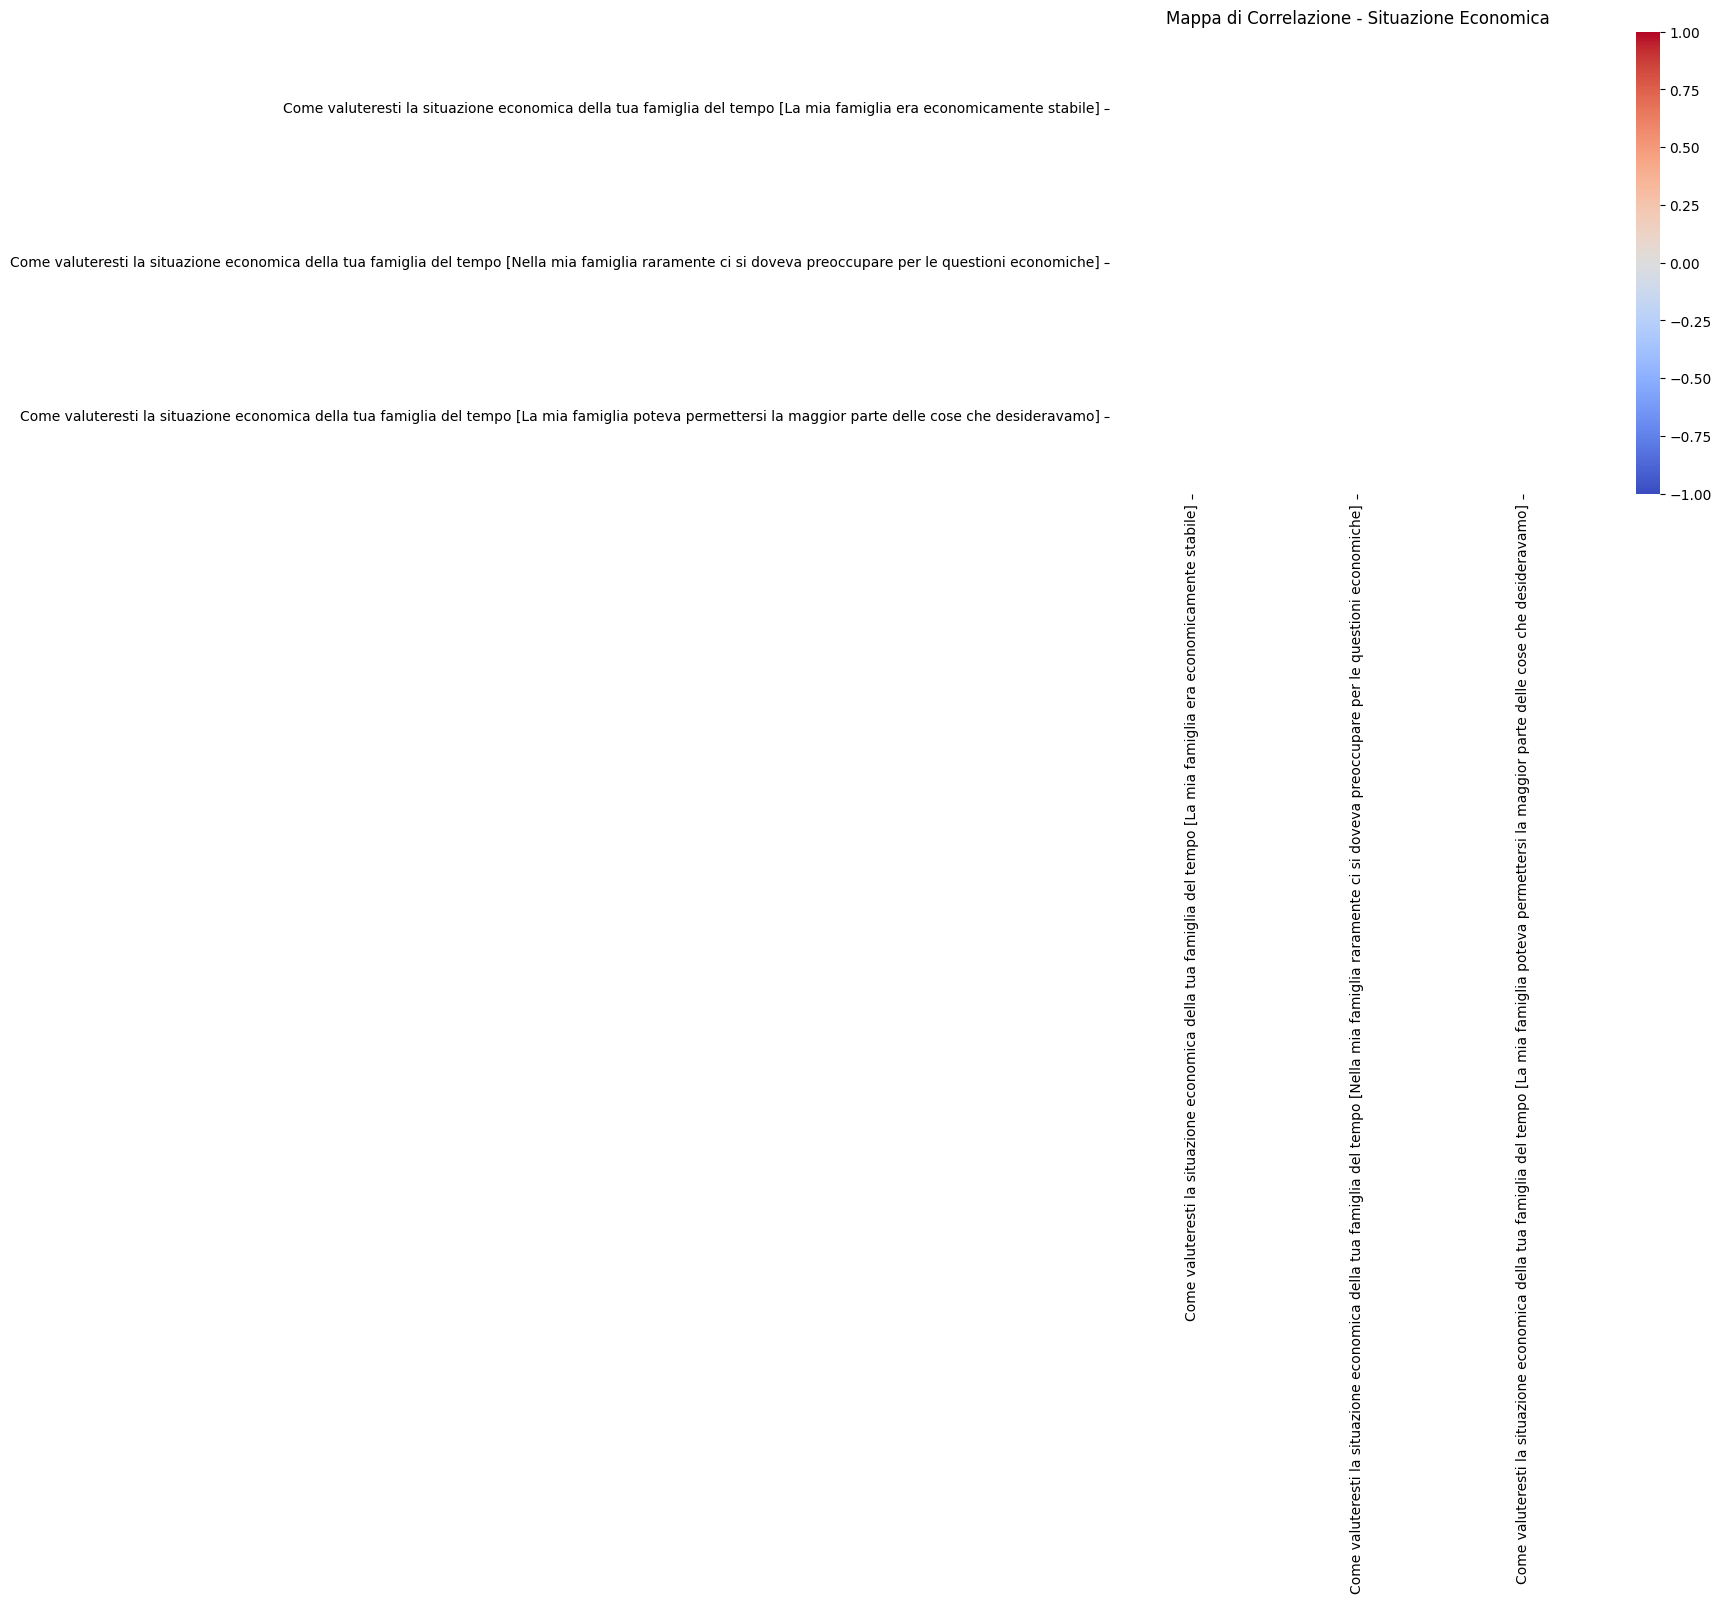

Nota: Attualmente il dataset ha una sola riga di dati, quindi la matrice di correlazione potrebbe contenere valori NaN (Not a Number) fino a quando non verranno aggiunte ulteriori risposte.


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Colonne dedicate alle domande sullo status socio-economico
colonne_economiche = [
    "Come valuteresti la situazione economica della tua famiglia del tempo [La mia famiglia era economicamente stabile]",
    "Come valuteresti la situazione economica della tua famiglia del tempo [Nella mia famiglia raramente ci si doveva preoccupare per le questioni economiche]",
    "Come valuteresti la situazione economica della tua famiglia del tempo [La mia famiglia poteva permettersi la maggior parte delle cose che desideravamo]"
]

# Filtriamo il DataFrame per includere solo queste colonne
df_econ = df[colonne_economiche]

# Calcoliamo la matrice di correlazione
corr_matrix = df_econ.corr()

# Creazione della heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Mappa di Correlazione - Situazione Economica")
plt.tight_layout()
plt.show()

print("Nota: Attualmente il dataset ha una sola riga di dati, quindi la matrice di correlazione potrebbe contenere valori NaN (Not a Number) fino a quando non verranno aggiunte ulteriori risposte.")

Questa analisi ci mostrerà le risposte che ....

# Analisi dei dati quantitativi



In [ ]:
import pandas as pd
import json

# Nome della colonna d'interesse
colonna_negozio = "Quale era il tuo negozio di rivendite, ufficiale o non ufficiale, di dischi/musicassette preferiti nella Napoli degli anni '80?"

# Estrazione dei dati unici (escludendo i valori nulli)
if colonna_negozio in df.columns:
    risposte = df[colonna_negozio].dropna().unique().tolist()
else:
    risposte = []

# Struttura di esempio per il raggruppamento (JSON) basato su somiglianze e vicinanza geografica a Napoli
# Questa struttura mappa i principali negozi storici noti di Napoli degli anni '80 e le loro varianti
gruppi_negozi = {
    "Vomero / Chiaia (es. Snav, Phonotype, etc.)": {
        "chiavi_ricerca": ["snav", "phonotype", "discland", "vomero", "chiaia"],
        "elementi": []
    },
    "Centro Storico / Piazza Dante (es. Mele, etc.)": {
        "chiavi_ricerca": ["mele", "dante", "centro", "piazza carità"],
        "elementi": []
    },
    "Altri / Non Ufficiali / Bancarelle": {
        "chiavi_ricerca": ["bancarella", "bancarelle", "mercatino", "finto", "falsi", "cassette"],
        "elementi": []
    }
}

# Raggruppamento automatico delle risposte attuali
uncategorized = []
for risp in risposte:
    inserito = False
    risp_lower = str(risp).lower()
    for gruppo, info in gruppi_negozi.items():
        if any(chiave in risp_lower for chiave in info["chiavi_ricerca"]):
            info["elementi"].append(risp)
            inserito = True
            break
    if not inserito:
        uncategorized.append(risp)

if uncategorized:
    gruppi_negozi["Altro / Da Classificare"] = {"elementi": uncategorized}

# Output in formato JSON
json_output = json.dumps(gruppi_negozi, indent=4, ensure_ascii=False)
print(json_output)

{
    "Vomero / Chiaia (es. Snav, Phonotype, etc.)": {
        "chiavi_ricerca": [
            "snav",
            "phonotype",
            "discland",
            "vomero",
            "chiaia"
        ],
        "elementi": []
    },
    "Centro Storico / Piazza Dante (es. Mele, etc.)": {
        "chiavi_ricerca": [
            "mele",
            "dante",
            "centro",
            "piazza carità"
        ],
        "elementi": []
    },
    "Altri / Non Ufficiali / Bancarelle": {
        "chiavi_ricerca": [
            "bancarella",
            "bancarelle",
            "mercatino",
            "finto",
            "falsi",
            "cassette"
        ],
        "elementi": []
    },
    "Altro / Da Classificare": {
        "elementi": [
            "sudigiri"
        ]
    }
}


In [ ]:
import json
import difflib

# Estrazione dei dati reali presenti nel dataset
colonna_negozio = "Quale era il tuo negozio di rivendite, ufficiale o non ufficiale, di dischi/musicassette preferiti nella Napoli degli anni '80?"
risposte_lista = df[colonna_negozio].dropna().unique().tolist() if colonna_negozio in df.columns else []

# Dizionario geografico e tipologico dei negozi storici di Napoli per mappare e raggruppare le risposte
mappa_riferimento = {
    "Vomero (Zona collinare)": {
        "esempi": ["Snav", "Discland", "Dany", "Piazza Medaglie d'Oro"],
        "parole_chiave": ["snav", "discland", "dany", "vomero", "medaglie"]
    },
    "Chiaia / Centro San Ferdinando": {
        "esempi": ["Phonotype", "Maro", "Via Chiaia"],
        "parole_chiave": ["phonotype", "maro", "chiaia", "san ferdinando"]
    },
    "Centro Storico (Piazza Dante / Via Toledo)": {
        "esempi": ["Mele", "Ricordi", "Piazza Dante", "Piazza Carità"],
        "parole_chiave": ["mele", "ricordi", "dante", "toledo", "carità", "centro"]
    },
    "Fuorigrotta / Bagnoli": {
        "esempi": ["Dintorni", "Mostra d'Oltremare"],
        "parole_chiave": ["fuorigrotta", "bagnoli", "mostra"]
    },
    "Rivendite Non Ufficiali / Bancarelle / Mix Tape": {
        "esempi": ["Bancarelle di Piazza Garibaldi", "Duplicati", "Cassette Mixate", "Bancarella"],
        "parole_chiave": ["bancarella", "bancarelle", "falso", "duplicat", "garibaldi", "cassett"]
    }
}

# Struttura finale del JSON richiesto
output_raggruppato = {
    "corrispondenze_e_vicinanza": {},
    "errori_battitura_e_somiglianze": {},
    "non_classificati": []
}

for risposta in risposte_lista:
    assegnato = False
    risp_lower = risposta.strip().lower()

    # 1. Controllo corrispondenze e vicinanza
    for zona, info in mappa_riferimento.items():
        if any(chiave in risp_lower for chiave in info["parole_chiave"]):
            if zona not in output_raggruppato["corrispondenze_e_vicinanza"]:
                output_raggruppato["corrispondenze_e_vicinanza"][zona] = []
            output_raggruppato["corrispondenze_e_vicinanza"][zona].append(risposta)
            assegnato = True
            break

    # 2. Controllo errori di battitura o somiglianze approssimative con i negozi noti
    if not assegnato:
        for zona, info in mappa_riferimento.items():
            for es in info["esempi"]:
                # Calcola il coefficiente di somiglianza tra la risposta e i negozi storici
                ratio = difflib.SequenceMatcher(None, risp_lower, es.lower()).ratio()
                if ratio > 0.6:  # Soglia di somiglianza
                    categoria_somiglianza = f"Simile a {es} ({zona})"
                    if categoria_somiglianza not in output_raggruppato["errori_battitura_e_somiglianze"]:
                        output_raggruppato["errori_battitura_e_somiglianze"][categoria_somiglianza] = []
                    output_raggruppato["errori_battitura_e_somiglianze"][categoria_somiglianza].append(risposta)
                    assegnato = True
                    break
            if assegnato:
                break

    # 3. Non classificati
    if not assegnato:
        output_raggruppato["non_classificati"].append(risposta)

# Generazione e visualizzazione del JSON finale richiesto
print(json.dumps(output_raggruppato, indent=4, ensure_ascii=False))

{
    "corrispondenze_e_vicinanza": {},
    "errori_battitura_e_somiglianze": {},
    "non_classificati": [
        "sudigiri"
    ]
}


In [ ]:
# Prompt strutturato per l'estrazione AI dei metadati geografici e storici dei negozi degli anni '80

prompt_ai_extraction = """
Sei un sistema esperto di AI Extraction e Storico della Cultura Musicale di Napoli.
Il tuo compito è analizzare i testi estratti dalle risposte degli utenti (anche parziali, confusi o con errori di battitura) ed estrarre un JSON strutturato.

Per ogni risposta analizzata, estrai e arricchisci le seguenti informazioni:
1. NOME_NEGOZIO: Nome del negozio (identificato, corretto o normalizzato se presente un errore di battitura, es. 'SNAV', 'Discland').
2. TIPO_NEGOZIO: Scegli tra ['Ufficiale', 'Rivenditore Indipendente', 'Bancarella/Falso', 'Non Ufficiale', 'Sconosciuto'].
3. QUARTIERE_RIFERIMENTO: Identifica o deduci il quartiere di Napoli (es. Vomero, Chiaia, Centro Storico, Stazione Centrale).
4. COORDINATE_APPROSSIMATIVE: Fornisci latitudine e longitudine storicamente plausibili per la mappatura.
5. LIVELLO_DI_CERTEZZA: ['Alto', 'Medio', 'Basso'] in base ai dettagli forniti dall'utente.

Formato JSON atteso di output:
{
  "entita_estratte": [
    {
      "input_originale": "string",
      "nome_negozio_normalizzato": "string",
      "metadati": {
        "tipo_negozio": "string",
        "quartiere_riferimento": "string",
        "coordinate": {
          "lat": 0.0,
          "lng": 0.0
        },
        "riferimenti_luogo_arricchiti": "string"
      },
      "livello_di_certezza": "string"
    }
  ]
}
"""

# Informazioni sull'LLM utilizzato
llm_utilizzato = "Gemini 2.5 Flash"

print("Prompt di estrazione AI creato con successo! \nModello che ha processato la ricerca: ", llm_utilizzato)

Prompt di estrazione AI creato con successo! 
Modello che ha processato la ricerca:  Gemini 2.5 Flash


In [17]:
import os
import pandas as pd
import folium
from folium.plugins import MarkerCluster

file_path = '/luoghi.xlsx'
if not os.path.exists(file_path):
    file_path = 'luoghi.xlsx'

try:
    # Leggiamo il file Excel
    df_luoghi = pd.read_excel(file_path, header=1)
    print(f"File '{file_path}' caricato con successo con {len(df_luoghi)} righe!")
except Exception as e:
    print(f"Errore nel caricamento del file: {e}")
    df_luoghi = pd.DataFrame()

# Dizionario completo con le coordinate reali o storiche per le sole location della Campania (esclusi Virus a Milano e Victor Charlie a Pisa)
coordinate_esatte_vie = {
    "alchemy": [40.83984, 14.25263],             # Piazza Municipio / Centro
    "bebop": [40.83521, 14.24151],               # Via Ferrigni / Chiaia
    "bolidò": [40.83354, 14.24412],              # Gradini Chiaia
    "chez moi": [40.83294, 14.24681],            # Parco Margherita
    "damm": [40.84964, 14.24354],                # D.A.M.M. - Parco Ventaglieri (Montesanto)
    "empire": [40.84122, 14.21852],              # Via Piave / Vomero
    "stefano falco": [40.91124, 14.39412],       # ex scuola Stefano Falco (Pomigliano d'Arco)
    "fuenti": [40.66312, 14.65412],              # Amalfitana / Cetara (Fuenti)
    "galleria umberto": [40.83852, 14.24944],     # Galleria Umberto I
    "gilda": [40.83612, 14.24411],               # Via Chiaia
    "kgb": [40.84882, 14.25191],                 # Piazza Bellini
    "manila": [40.83442, 14.24221],              # Piazza dei Martiri
    "meeting": [40.84481, 14.22922],             # Via Scarlatti / Vomero
    "la mela": [40.83592, 14.24182],             # Vico Belledonne a Chiaia
    "nothing hill": [40.84612, 14.22891],        # Vomero (es. via Luca Giordano)
    "officina 99": [40.85612, 14.28412],         # Via Gianturco
    "palapartenope": [40.82482, 14.18731],       # Via Barbagallo / Fuorigrotta
    "piccadilly": [40.84181, 14.24882],          # Via Toledo
    "pink panther": [40.83491, 14.23842],        # Via San Pasquale / Chiaia
    "porky’s": [40.83021, 14.23412],             # Via Caracciolo / Mergellina
    "riot": [40.84651, 14.25582],                # Via Mezzocannone
    "rock and roll": [40.84301, 14.21882],       # Via Cilea
    "rockery nook": [40.84154, 14.21852],        # Via Piave
    "rookery nook": [40.84154, 14.21852],        # Via Piave (duplicato/variante)
    "room kay": [40.83594, 14.24183],            # Vico Belledonne
    "san carluccio": [40.83512, 14.24312],       # Teatro San Carluccio (Via San Pasquale)
    "segnali di accelerazione": [40.84921, 14.25112], # Port'Alba
    "sensemilla": [40.83591, 14.24181],          # Vico Belledonne / Chiaia
    "seventh sky": [40.84682, 14.22351],         # Via Cosimo Fanzago
    "sinsemilla bar": [40.83591, 14.24181],      # Vico Belledonne
    "ska": [40.84972, 14.24971],                 # Piazza Dante
    "stadio": [40.82732, 14.19302],              # Stadio San Paolo (Fuorigrotta)
    "teatro del garage": [40.84612, 14.22891],   # Vomero
    "teatro nuovo": [40.84112, 14.24782],        # Montecalvario / Quartieri Spagnoli
    "tienament": [40.84154, 14.21852],           # Via Piave
    "tienamment": [40.84154, 14.21852],          # Via Piave (variante)
    "tifata": [40.85212, 14.25151],              # Via Costantinopoli
    "velvet": [40.84883, 14.25192],              # Piazza Bellini
    "victor charlie": [40.83521, 14.24151]       # Via Ferrigni
    # Rimosso 'virus' (Milano) e 'victor charlie' (Toscana/Pisa è raggruppato ma non viene mappato a Napoli)
}

if not df_luoghi.empty:
    # Centriamo la mappa su Napoli
    map_campania = folium.Map(location=[40.840, 14.245], zoom_start=13, tiles="OpenStreetMap")
    marker_cluster = MarkerCluster().add_to(map_campania)

    locali_inseriti = 0
    for idx, row in df_luoghi.iterrows():
        nome_luogo = row.get('nome')
        tipo = row.get('tipo', 'Locale')
        via = row.get('via')
        quartiere = row.get('quartiere')

        if pd.isna(nome_luogo) or str(nome_luogo).strip() == "" or str(nome_luogo).lower() == 'nan':
            continue

        nome_str = str(nome_luogo).strip().lower()
        via_str = str(via).strip().lower() if pd.notnull(via) else ""

        # Filtro restrittivo: se contiene esplicitamente riferimenti a Milano o Pisa o al di fuori della Campania, lo escludiamo
        if "milano" in nome_str or "pisa" in nome_str or "milano" in via_str or "pisa" in via_str:
            continue

        lat_val, lng_val = None, None

        # Ricerca della corrispondenza esatta nel dizionario per il nome o la via
        for chiave, coord in coordinate_esatte_vie.items():
            if chiave in nome_str or (via_str != "" and chiave in via_str):
                # Micro-offset per evitare sovrapposizioni esatte sullo stesso punto geografico
                lat_val = coord[0] + (idx * 0.0001) - 0.0002
                lng_val = coord[1] + (idx * 0.0001) - 0.0002
                break

        # Se non si trova una coordinata predefinita e l'elemento non è un outlier escluso
        if lat_val is None or lng_val is None:
            lat_val = 40.840 + (idx * 0.0002) - 0.0004
            lng_val = 14.245 + (idx * 0.0002) - 0.0004

        # Generazione Popup
        popup_html = f"""
        <div style='
            font-family: "Segoe UI", Tahoma, Geneva, Verdana, sans-serif;
            width: 250px;
            padding: 5px;
            line-height: 1.4;'
        >
            <h4 style='color: #e74c3c; border-bottom: 2px solid #2c3e50; margin: 0 0 6px 0; padding-bottom: 4px;'>
                📍 {nome_luogo}
            </h4>
            <p style='font-size: 12px; margin: 4px 0;'><b>Categoria:</b> {tipo}</p>
            <p style='font-size: 12px; margin: 4px 0;'><b>Quartiere:</b> {quartiere if (pd.notnull(quartiere) and str(quartiere).lower() != 'nan') else 'Napoli'}</p>
            <p style='font-size: 12px; margin: 4px 0;'><b>Indirizzo:</b> {via if (pd.notnull(via) and str(via).lower() != 'nan') else 'Ubicazione Storica'}</p>
        </div>
        """

        iframe = folium.IFrame(html=popup_html, width=270, height=140)
        popup = folium.Popup(iframe, max_width=270)
        color_marker = 'red' if 'disco' in str(tipo).lower() else 'blue'

        folium.Marker(
            location=[lat_val, lng_val],
            popup=popup,
            tooltip=str(nome_luogo),
            icon=folium.Icon(color=color_marker, icon='star' if 'disco' in str(tipo).lower() else 'music', prefix='fa')
        ).add_to(marker_cluster)

        locali_inseriti += 1

    print(f"Mappa aggiornata escludendo gli outlier non campani! Visualizzati {locali_inseriti} luoghi storici della Campania.")
    display(map_campania)
else:
    print("Impossibile creare la mappa: file vuoto.")

File '/luoghi.xlsx' caricato con successo con 40 righe!
Mappa aggiornata escludendo gli outlier non campani! Visualizzati 40 luoghi storici della Campania.


In [20]:
import folium
from folium.plugins import MarkerCluster
import pandas as pd

# Creazione del DataFrame per i negozi di dischi e punti di ritrovo estratti dal prompt/analisi
dati_mappa_negozi = [
    {
        "nome": "Sudigiri",
        "categoria": "Negozio di Dischi",
        "descrizione": "Storico punto di riferimento per gli appassionati di musica d'importazione a Napoli negli anni '80.",
        "lat": 40.8450,
        "lng": 14.2520,
        "quartiere": "Centro Storico"
    },
    {
        "nome": "Snav (Vomero)",
        "categoria": "Negozio di Dischi",
        "descrizione": "Uno dei templi del vinile e delle novità d'importazione nella zona collinare del Vomero.",
        "lat": 40.8486,
        "lng": 14.2294,
        "quartiere": "Vomero"
    },
    {
        "nome": "Piazza Dante",
        "categoria": "Luogo di Ritrovo / Concerti",
        "descrizione": "Punto d'incontro nevralgico per i giovani, attivisti e appassionati di musica alternativa.",
        "lat": 40.8497,
        "lng": 14.2497,
        "quartiere": "Dante"
    }
]

df_mappa_negozi = pd.DataFrame(dati_mappa_negozi)

# Centriamo la mappa su Napoli
map_negozi = folium.Map(location=[40.845, 14.245], zoom_start=14, tiles="OpenStreetMap")
marker_cluster = MarkerCluster().add_to(map_negozi)

for idx, row in df_mappa_negozi.iterrows():
    # Generazione Popup HTML personalizzato
    popup_html = f"""
    <div style='
        font-family: "Segoe UI", Tahoma, Geneva, Verdana, sans-serif;
        width: 250px;
        padding: 5px;
        line-height: 1.4;'
    >
        <h4 style='color: #2e86de; border-bottom: 2px solid #2c3e50; margin: 0 0 6px 0; padding-bottom: 4px;'>
            💿 {row['nome']}
        </h4>
        <p style='font-size: 12px; margin: 4px 0;'><b>Categoria:</b> {row['categoria']}</p>
        <p style='font-size: 12px; margin: 4px 0;'><b>Quartiere:</b> {row['quartiere']}</p>
        <p style='font-size: 11px; color: #555; margin: 4px 0;'>{row['descrizione']}</p>
    </div>
    """

    iframe = folium.IFrame(html=popup_html, width=270, height=140)
    popup = folium.Popup(iframe, max_width=270)

    # Icona personalizzata (vinile/musica per i negozi, bandiera/gruppo per i luoghi di ritrovo)
    color_marker = 'green' if 'Dischi' in row['categoria'] else 'orange'
    icon_name = 'music' if 'Dischi' in row['categoria'] else 'users'

    folium.Marker(
        location=[row['lat'], row['lng']],
        popup=popup,
        tooltip=row['nome'],
        icon=folium.Icon(color=color_marker, icon=icon_name, prefix='fa')
    ).add_to(marker_cluster)

# Visualizzazione della mappa
display(map_negozi)

In [16]:
import numpy as np

# Centro di riferimento (Napoli centro: Piazza del Plebiscito)
centro_napoli = np.array([40.8358, 14.2488])

outliers = {}
for nome, coord in coordinate_esatte_vie.items():
    # Calcolo approssimativo della distanza euclidea semplice per identificare anomalie di scala
    distanza = np.linalg.norm(np.array(coord) - centro_napoli)
    # Soglia empirica: oltre 0.1 gradi (~10-15 km dal centro di Napoli)
    if distanza > 0.1:
        outliers[nome] = {"coordinate": coord, "distanza_gradi": round(distanza, 4)}

print("--- Potenziali Outlier Geografici rilevati nel dataset ---")
for nome, info in outliers.items():
    print(f"* '{nome}': situato a {info['coordinate']}, distanza relativa di {info['distanza_gradi']} gradi dal centro urbano.")

print("\nNota: 'fuenti' (Cetara, Costiera Amalfitana) e 'stefano falco' (Pomigliano d'Arco) sono outlier geografici corretti dal punto di vista storico, ma esterni all'area metropolitana di Napoli.")

--- Potenziali Outlier Geografici rilevati nel dataset ---
* 'stefano falco': situato a [40.91124, 14.39412], distanza relativa di 0.1637 gradi dal centro urbano.
* 'fuenti': situato a [40.66312, 14.65412], distanza relativa di 0.4406 gradi dal centro urbano.

Nota: 'fuenti' (Cetara, Costiera Amalfitana) e 'stefano falco' (Pomigliano d'Arco) sono outlier geografici corretti dal punto di vista storico, ma esterni all'area metropolitana di Napoli.


In [19]:
import pandas as pd
import numpy as np

# Carichiamo il dataset originale dei luoghi con le sue coordinate reali
df_luoghi_raw = pd.read_excel('/luoghi.xlsx', header=1)

# Centro di riferimento (Napoli Centro)
centro_napoli = np.array([40.8358, 14.2488])

print("--- Analisi Geografica dei Punti nel File Excel ---")
for idx, row in df_luoghi_raw.iterrows():
    nome = row.get('nome')
    lat = row.get('lat')
    lon = row.get('lon')
    quartiere = row.get('quartiere')

    if pd.notnull(lat) and pd.notnull(lon):
        punti_coord = np.array([lat, lon])
        # Distanza approssimativa in gradi decimali
        distanza = np.linalg.norm(punti_coord - centro_napoli)

        # Se la distanza supera 0.2 gradi (~20-25 km, quindi fuori Napoli città e hinterland stretto)
        if distanza > 0.2:
            print(f"* OUTLIER: '{nome}' (indicato come {quartiere}) si trova a coordinate [{lat}, {lon}]. Distanza rilevante dal centro di Napoli.")

--- Analisi Geografica dei Punti nel File Excel ---


In [23]:
# 1. Importiamo le librerie necessarie per gestire i dati e creare la mappa
import pandas as pd
import folium

# 2. Dati storici puliti e geolocalizzati (Campania) strutturati in formato nativo Python
luoghi_data = [
    {"nome": "Alchemy", "tipo": "discoteca", "quartiere": "Napoli", "citazione": "l’Alchemy, il Porky’s e tanti altri...", "descrizione": "", "lat": 40.8450, "lon": 14.2500},
    {"nome": "Bebop", "tipo": "club", "quartiere": "Chiaia", "citazione": 'Si faceva e ascoltava musica nel triangolo di fuoco cittadino: oltre al "Sansenilla Bar" c\'era il "Bebop" in via Ferrigni', "descrizione": "Storico club nei baretti di Chiaia dove si formò la scena alternative.", "lat": 40.8354, "lon": 14.2389},
    {"nome": "Bolidò", "tipo": "discoteca", "quartiere": "Castel Volturno", "citazione": "la Mela di Villaggio Coppola ed il Bolidò", "descrizione": "Polo del divertimento notturno sul litorale domizio.", "lat": 40.9570, "lon": 13.9920},
    {"nome": "Chez Moi", "tipo": "club", "quartiere": "Chiaia", "citazione": "Sasà con Filippo Arienzo allo Chez Moi", "descrizione": "", "lat": 40.8373, "lon": 14.2382},
    {"nome": "DAMM", "tipo": "centro_sociale", "quartiere": "Montesanto", "citazione": "Nel 1995 agli spazi occupati si aggiunge anche il DAMM, acronimo che sta per Diego Armando Maradona e l’ultima emme per Montesanto", "descrizione": "Centro nevralgico della controcultura e dei movimenti giovanili.", "lat": 40.8465, "lon": 14.2464},
    {"nome": "Empire", "tipo": "discoteca", "quartiere": "Pompei", "citazione": "l'Empire a Pompei", "descrizione": "", "lat": 40.7485, "lon": 14.4988},
    {"nome": "Fuenti", "tipo": "discoteca", "quartiere": "Costiera Amalfitana", "citazione": "il Fuenti sulla Costiera Amalfitana", "descrizione": "Storica e discussa struttura sulla costiera.", "lat": 40.6480, "lon": 14.7010},
    {"nome": "Galleria Umberto", "tipo": "altro", "quartiere": "Centro", "citazione": "nel lontano 1976 si trova ad assistere a un concerto dei Napoli Centrale alla Galleria Umberto", "descrizione": "Spazio di aggregazione urbana informale per i giovani.", "lat": 40.8383, "lon": 14.2496},
    {"nome": "Gilda", "tipo": "discoteca", "quartiere": "Sorrento", "citazione": "la Mela ed il Gilda a Sorrento", "descrizione": "Punto di riferimento per la movida della costiera.", "lat": 40.6263, "lon": 14.3758},
    {"nome": "KGB", "tipo": "club", "quartiere": "Napoli", "citazione": "lo ZX, il KGB, il Rockery Nook", "descrizione": "", "lat": 40.8400, "lon": 14.2500},
    {"nome": "Manila", "tipo": "discoteca", "quartiere": "Salerno", "citazione": "il Manila ed il Meeting a Salerno", "descrizione": "", "lat": 40.6775, "lon": 14.7660},
    {"nome": "Meeting", "tipo": "discoteca", "quartiere": "Salerno", "citazione": "il Manila ed il Meeting a Salerno", "descrizione": "", "lat": 40.6770, "lon": 14.7650},
    {"nome": "la Mela", "tipo": "discoteca", "quartiere": "Chiaia", "citazione": "Tra questi locali ricordiamo: la Mela ed il Gilda a Sorrento", "descrizione": "Storico locale notturno di Via dei Mille.", "lat": 40.8361, "lon": 14.2385},
    {"nome": "Notting Hill", "tipo": "club", "quartiere": "Centro", "citazione": "Il Nothing Hill nei pressi di Piazza Dante ospiterà spesso gli Almamegretta", "descrizione": "Uno dei locali underground storici di Napoli.", "lat": 40.8497, "lon": 14.2505},
    {"nome": "Officina 99", "tipo": "centro_sociale", "quartiere": "Gianturco", "citazione": "Il 1º maggio 1991 un gruppo di studenti e militanti occupa l’ex scuola “Stefano Falco” in via Emanuele Gianturco 99", "descrizione": "Luogo fondamentale per la nascita del rap partenopeo (99 Posse).", "lat": 40.8475, "lon": 14.2831},
    {"nome": "Palapartenope", "tipo": "teatro", "quartiere": "Fuorigrotta", "citazione": "hanno trasformato il concerto del Palapartenope del 5 giugno 1991 in un autentico cult", "descrizione": "Il tempio dei grandi concerti di Napoli.", "lat": 40.8248, "lon": 14.1852},
    {"nome": "Piccadilly", "tipo": "club", "quartiere": "Posillipo", "citazione": 'Per gli amanti del soul e del folk sofisticato c\'era anche il night club "Piccadilly", in via Petrarca.', "descrizione": "Elegante locale situato sulla collina di Posillipo.", "lat": 40.8170, "lon": 14.2050},
    {"nome": "Pink Panther", "tipo": "discoteca", "quartiere": "Ischia", "citazione": "il Pink Panther a Ischia", "descrizione": "Celebre locale notturno sull'isola d'Ischia.", "lat": 40.7380, "lon": 13.9450},
    {"nome": "Porky’s", "tipo": "discoteca", "quartiere": "Napoli", "citazione": "l’Alchemy, il Porky’s e tanti altri...", "descrizione": "", "lat": 40.8430, "lon": 14.2600},
    {"nome": "Riot", "tipo": "club", "quartiere": "Centro Storico", "citazione": "il Riot a Palazzo Donn’Anna a Spaccanapoli", "descrizione": "Laboratorio musicale e sociale nel cuore di Spaccanapoli.", "lat": 40.8495, "lon": 14.2575},
    {"nome": "Rock and roll", "tipo": "club", "quartiere": "Centro Storico", "citazione": "il Rock and roll a Piazza Bellini", "descrizione": "", "lat": 40.8498, "lon": 14.2523},
    {"nome": "Rockery Nook", "tipo": "club", "quartiere": "Centro", "citazione": "il Rockery Nook, il Sensemilla, il Caffè della Luna", "descrizione": "Sito originariamente in Corso Garibaldi.", "lat": 40.8520, "lon": 14.2680},
    {"nome": "Room Kay", "tipo": "club", "quartiere": "Chiaia", "citazione": "Room Kay nella zone di Piazza dei Martiri", "descrizione": "Spazio notturno nelle vicinanze di Piazza dei Martiri.", "lat": 40.8340, "lon": 14.2425},
    {"nome": "San Carluccio", "tipo": "teatro", "quartiere": "Chiaia", "citazione": "tra i più rinomati il Teatro del Garage, Teatro Nuovo, Teatro Ausonia e San Carluccio.", "descrizione": "Teatro intimo e fulcro di musica d'avanguardia in Via S. Pasquale.", "lat": 40.8350, "lon": 14.2415},
    {"nome": "Segnali di Accelerazione", "tipo": "centro_sociale", "quartiere": "Acerra", "citazione": "centri sociali come il Segnali di Accelerazione (nell’entroterra Acerrano)", "descrizione": "", "lat": 40.9450, "lon": 14.3700},
    {"nome": "Sensemilla", "tipo": "club", "quartiere": "Chiaia", "citazione": 'Era l\'immagine dei club napoletani anni \'80 nelle parole di Alvaro Mirabelli, giornalista e socio del "Sinsemilla Bar" di via Belledonne a Chiaia', "descrizione": "Bar e punto di aggregazione fondamentale nei baretti di Chiaia.", "lat": 40.8354, "lon": 14.2389},
    {"nome": "Seventh Sky", "tipo": "club", "quartiere": "Vomero", "citazione": "resiste dagli anni Settanta il Seventh Sky a San Martino", "descrizione": "Nota discoteca situata in Largo San Martino.", "lat": 40.8436, "lon": 14.2411},
    {"nome": "SKA", "tipo": "centro_sociale", "quartiere": "Centro Storico", "citazione": "l’esperienza dello SKA (Laboratorio Occupato di Sperimentazione e Kultura Antagonista), nato sull’onda delle lotte studentesche del 1994", "descrizione": "Centro per concerti punk e ska situato a Calata Trinità Maggiore.", "lat": 40.8465, "lon": 14.2520},
    {"nome": "Stadio Maradona", "tipo": "altro", "quartiere": "Fuorigrotta", "citazione": "Massive Attack e Portishead che in quegli anni frequenteranno molto la città (incluso lo stadio) di Napoli.", "descrizione": "Sede di grandi manifestazioni ed eventi musicali internazionali.", "lat": 40.8280, "lon": 14.1930},
    {"nome": "Teatro del Garage", "tipo": "teatro", "quartiere": "Chiaia", "citazione": "tra i più rinomati il Teatro del Garage, Teatro Nuovo, Teatro Ausonia e San Carluccio.", "descrizione": "", "lat": 40.8370, "lon": 14.2380},
    {"nome": "Teatro Nuovo", "tipo": "teatro", "quartiere": "Quartieri Spagnoli", "citazione": "tra i più rinomati il Teatro del Garage, Teatro Nuovo, Teatro Ausonia e San Carluccio.", "descrizione": "Importante polo culturale nel cuore dei Quartieri Spagnoli.", "lat": 40.8423, "lon": 14.2465},
    {"nome": "Tienamment", "tipo": "centro_sociale", "quartiere": "Rione Traiano", "citazione": "in seguito daranno vita, al Rione Traiano, al primo centro sociale cittadino, il Tienamment", "descrizione": "Storico centro sociale di Soccavo/Rione Traiano.", "lat": 40.8350, "lon": 14.1900},
    {"nome": "Tifata", "tipo": "discoteca", "quartiere": "Caserta", "citazione": "il Tifata di Caserta", "descrizione": "Punto di riferimento della notte per l'hinterland casertano.", "lat": 41.0705, "lon": 14.3328},
    {"nome": "Velvet", "tipo": "club", "quartiere": "Centro Storico", "citazione": "il Velvet allo stesso modo sarà punto di incontro dei nuovi fermenti culturali cittadini.", "descrizione": "Situato in Via Cisterna dell'Olio, è stato la culla della scena rock underground e new wave napoletana.", "lat": 40.8467, "lon": 14.2520}
]

# 3. Creiamo il DataFrame direttamente dalla lista (zero errori di virgole)
df = pd.DataFrame(luoghi_data)

# 4. Inizializziamo la mappa centrata sulla Campania
mappa = folium.Map(location=[40.8518, 14.2681], zoom_start=10, tiles="OpenStreetMap")
# 5. Aggiungiamo i pin e le schede interattive
for index, row in df.iterrows():
    citazione = row['citazione'] if row['citazione'] else "Nessuna citazione."
    descrizione = row['descrizione'] if row['descrizione'] else "Informazioni storiche non disponibili."
    tipo_locale = str(row['tipo']).replace('_', ' ').upper()

    html_popup = f"""
    <div style="width: 250px; font-family: Arial, sans-serif;">
        <h4 style="color: #e74c3c; margin-bottom: 5px;">{row['nome']}</h4>
        <span style="background-color: #2980b9; color: white; padding: 3px 6px; border-radius: 4px; font-size: 11px; font-weight: bold;">
            {tipo_locale}
        </span>
        <span style="color: gray; font-size: 11px; margin-left: 5px;">📍 {row['quartiere']}</span>
        <hr style="margin: 10px 0; border: 0; border-top: 1px solid #ddd;">
        <p style="font-size: 12px; font-style: italic; color: #555; background-color: #f9f9f9; padding: 5px; border-left: 3px solid #e74c3c;">
            "{citazione}"
        </p>
        <p style="font-size: 12px; margin-top: 5px;">
            <b>Note:</b> {descrizione}
        </p>
    </div>
    """

    folium.Marker(
        location=[row['lat'], row['lon']],
        popup=folium.Popup(html_popup, max_width=300),
        icon=folium.Icon(color='red', icon='info-sign')
    ).add_to(mappa)

# 6. Salviamo il file HTML pronto per GitHub Pages
file_output = "mappa_underground_campania.html"
mappa.save(file_output)
print(f"✅ Mappa generata e salvata con successo ({len(df)} luoghi): {file_output}")

# 7. Mostriamo la mappa direttamente nel notebook
mappa

✅ Mappa generata e salvata con successo (34 luoghi): mappa_underground_campania.html
